# Ames Housing: Sale Price Prediction

**Goal:** Compare a range of regression models, from linear models to boosted trees, and identify which predicts SalePrice most accurately for the Kaggle House Prices: Advanced Regression Techniques dataset (Ames, Iowa). Models are tuned with cross-validation and ranked by RMSLE (error on the log scale), with dollar RMSE, MAE and R² on a held-out test set as a check.

**Workflow**

1. Setup and configuration
2. Load data and check missing values
3. Clean missing values (`clean_missing`)
4. Quick EDA: target, correlations, skew
5. Feature engineering (`engineer_features`)
6. Train/test split
7. Models and search spaces
8. Tune every model with cross-validation (CV)
9. Compare models: CV score, test score, noise
10. Conclusion and Limitations

## 1. Setup and configuration

In [100]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import (
    train_test_split, GridSearchCV,RandomizedSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import ElasticNet, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor, AdaBoostRegressor, GradientBoostingRegressor
)
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error,r2_score
)
from scipy.stats import randint, uniform, loguniform, skew
from sklearn.pipeline import Pipeline

import xgboost as xgb
from xgboost import  XGBRegressor

## 2. Load data and check missing values

Note: pandas reads the text `NA` in the CSV as a missing value. In this dataset `NA` usually means "this house does not have that feature" (no pool, no alley, and so on), so the NaNs are meaningful.

In [46]:
with open(r"D:\Python files\projects\advanced housing price prediction\data_description.txt") as new_file:
    desc = new_file.read()

In [3]:
print(desc)

MSSubClass: Identifies the type of dwelling involved in the sale.	

        20	1-STORY 1946 & NEWER ALL STYLES
        30	1-STORY 1945 & OLDER
        40	1-STORY W/FINISHED ATTIC ALL AGES
        45	1-1/2 STORY - UNFINISHED ALL AGES
        50	1-1/2 STORY FINISHED ALL AGES
        60	2-STORY 1946 & NEWER
        70	2-STORY 1945 & OLDER
        75	2-1/2 STORY ALL AGES
        80	SPLIT OR MULTI-LEVEL
        85	SPLIT FOYER
        90	DUPLEX - ALL STYLES AND AGES
       120	1-STORY PUD (Planned Unit Development) - 1946 & NEWER
       150	1-1/2 STORY PUD - ALL AGES
       160	2-STORY PUD - 1946 & NEWER
       180	PUD - MULTILEVEL - INCL SPLIT LEV/FOYER
       190	2 FAMILY CONVERSION - ALL STYLES AND AGES

MSZoning: Identifies the general zoning classification of the sale.
		
       A	Agriculture
       C	Commercial
       FV	Floating Village Residential
       I	Industrial
       RH	Residential High Density
       RL	Residential Low Density
       RP	Residential Low Density Park 
       RM

In [47]:
df = pd.read_csv(r"D:\Python files\projects\advanced housing price prediction\train.csv")

In [48]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [6]:
df.columns.sort_values()

Index(['1stFlrSF', '2ndFlrSF', '3SsnPorch', 'Alley', 'BedroomAbvGr',
       'BldgType', 'BsmtCond', 'BsmtExposure', 'BsmtFinSF1', 'BsmtFinSF2',
       'BsmtFinType1', 'BsmtFinType2', 'BsmtFullBath', 'BsmtHalfBath',
       'BsmtQual', 'BsmtUnfSF', 'CentralAir', 'Condition1', 'Condition2',
       'Electrical', 'EnclosedPorch', 'ExterCond', 'ExterQual', 'Exterior1st',
       'Exterior2nd', 'Fence', 'FireplaceQu', 'Fireplaces', 'Foundation',
       'FullBath', 'Functional', 'GarageArea', 'GarageCars', 'GarageCond',
       'GarageFinish', 'GarageQual', 'GarageType', 'GarageYrBlt', 'GrLivArea',
       'HalfBath', 'Heating', 'HeatingQC', 'HouseStyle', 'Id', 'KitchenAbvGr',
       'KitchenQual', 'LandContour', 'LandSlope', 'LotArea', 'LotConfig',
       'LotFrontage', 'LotShape', 'LowQualFinSF', 'MSSubClass', 'MSZoning',
       'MasVnrArea', 'MasVnrType', 'MiscFeature', 'MiscVal', 'MoSold',
       'Neighborhood', 'OpenPorchSF', 'OverallCond', 'OverallQual',
       'PavedDrive', 'PoolArea', 'Po

In [7]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


## 3. Clean missing values

Before filling anything, verify the assumption "a missing quality column means the house has no such feature". For each pair below, the number of NaN rows that still have a non-zero size/count should be 0.

In [8]:
def null_df(df):
    nullc = df.isnull().sum()
    nullp = round(100 * df.isnull().sum()/len(df),2)
    na = pd.DataFrame({'Null Count':nullc, 'Null percent':nullp})
    na = na[na['Null Count'] >0]

    return na.sort_values('Null Count', ascending = False )

In [9]:
null_df(df)

,Null Count,Null percent
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


<Axes: xlabel='PoolQC', ylabel='SalePrice'>

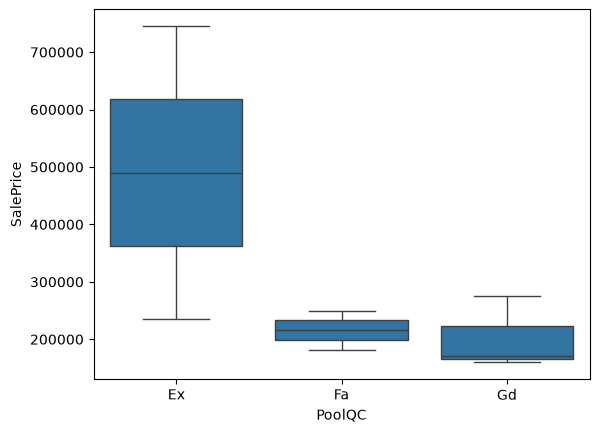

In [10]:
sns.boxplot(data = df, x = 'PoolQC', y = 'SalePrice')

In [11]:
df[df['PoolQC'].isna()]['PoolArea'].value_counts()

PoolArea
0    1453
Name: count, dtype: int64

In [49]:
# Most homes do not have a pool so pool QC is null for almost all
df['PoolQC'] = df['PoolQC'].fillna('NA')

In [14]:
null_df(df)

,Null Count,Null percent
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageCond,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


In [15]:
df['Alley'].value_counts()

Alley
Grvl    50
Pave    41
Name: count, dtype: int64

In [50]:
df[['MiscFeature','Alley','Fence','MasVnrType']] = df[['MiscFeature','Alley','Fence','MasVnrType']].fillna('NA')

In [17]:
null_df(df)

,Null Count,Null percent
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageYrBlt,81,5.55
GarageFinish,81,5.55
GarageType,81,5.55
GarageQual,81,5.55
GarageCond,81,5.55
BsmtExposure,38,2.60
BsmtFinType2,38,2.60
BsmtCond,37,2.53


In [18]:
df[df['FireplaceQu'].isna()]['Fireplaces'].value_counts()

Fireplaces
0    690
Name: count, dtype: int64

In [51]:
df['FireplaceQu'] = df['FireplaceQu'].fillna('NA')

In [20]:
null_df(df)

,Null Count,Null percent
LotFrontage,259,17.74
GarageYrBlt,81,5.55
GarageFinish,81,5.55
GarageQual,81,5.55
GarageType,81,5.55
GarageCond,81,5.55
BsmtFinType2,38,2.60
BsmtExposure,38,2.60
BsmtQual,37,2.53
BsmtFinType1,37,2.53


In [21]:
df[df['LotFrontage'].isna()].head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
7,8,60,RL,NaN,10382,Pave,NA,IR1,Lvl,AllPub,...,0,NA,NA,Shed,350,11,2009,WD,Normal,200000
12,13,20,RL,NaN,12968,Pave,NA,IR2,Lvl,AllPub,...,0,NA,NA,NA,0,9,2008,WD,Normal,144000
14,15,20,RL,NaN,10920,Pave,NA,IR1,Lvl,AllPub,...,0,NA,GdWo,NA,0,5,2008,WD,Normal,157000
16,17,20,RL,NaN,11241,Pave,NA,IR1,Lvl,AllPub,...,0,NA,NA,Shed,700,3,2010,WD,Normal,149000
24,25,20,RL,NaN,8246,Pave,NA,IR1,Lvl,AllPub,...,0,NA,MnPrv,NA,0,5,2010,WD,Normal,154000


In [22]:
df[df['LotFrontage'].isna()]['BldgType'].value_counts()

BldgType
1Fam      226
TwnhsE     22
Duplex      5
Twnhs       3
2fmCon      3
Name: count, dtype: int64

In [23]:
pd.crosstab(df['LotFrontage'], df['Street'], dropna = False)

Street,Grvl,Pave
LotFrontage,,
21.0,0,23
24.0,0,19
30.0,0,6
32.0,0,5
33.0,0,1
...,...,...
168.0,0,1
174.0,0,2
182.0,0,1


In [24]:
df.corr(numeric_only = True)['LotFrontage'].sort_values()

MSSubClass      -0.386347
OverallCond     -0.059213
Id              -0.010601
BsmtHalfBath    -0.007234
KitchenAbvGr    -0.006069
MiscVal          0.003368
YrSold           0.007450
EnclosedPorch    0.010700
MoSold           0.011200
LowQualFinSF     0.038469
ScreenPorch      0.041383
BsmtFinSF2       0.049900
HalfBath         0.053532
3SsnPorch        0.070029
GarageYrBlt      0.070250
2ndFlrSF         0.080177
WoodDeckSF       0.088521
YearRemodAdd     0.088866
BsmtFullBath     0.100949
YearBuilt        0.123349
BsmtUnfSF        0.132644
OpenPorchSF      0.151972
MasVnrArea       0.193458
FullBath         0.198769
PoolArea         0.206167
BsmtFinSF1       0.233633
OverallQual      0.251646
BedroomAbvGr     0.263170
Fireplaces       0.266639
GarageCars       0.285691
GarageArea       0.344997
SalePrice        0.351799
TotRmsAbvGrd     0.352096
TotalBsmtSF      0.392075
GrLivArea        0.402797
LotArea          0.426095
1stFlrSF         0.457181
LotFrontage      1.000000
Name: LotFro

In [25]:
df.groupby('BldgType')['LotFrontage'].mean().sort_values()

BldgType
Twnhs     24.675000
TwnhsE    41.978261
2fmCon    66.428571
Duplex    71.595745
1Fam      74.503018
Name: LotFrontage, dtype: float64

In [26]:
df.groupby('Neighborhood')['LotFrontage'].mean().sort_values()

Neighborhood
BrDale     21.562500
Blueste    24.000000
MeadowV    27.800000
NPkVill    32.285714
Blmngtn    47.142857
BrkSide    57.509804
SWISU      58.913043
Veenker    59.714286
IDOTRR     62.500000
StoneBr    62.700000
OldTown    62.788991
Somerst    64.666667
Edwards    68.217391
Mitchel    70.083333
SawyerW    71.500000
CollgCr    71.682540
Crawfor    71.804878
Sawyer     74.437500
NAmes      76.462366
Gilbert    79.877551
Timber     80.133333
NWAmes     81.288889
NridgHt    81.881579
ClearCr    83.461538
NoRidge    91.878788
Name: LotFrontage, dtype: float64

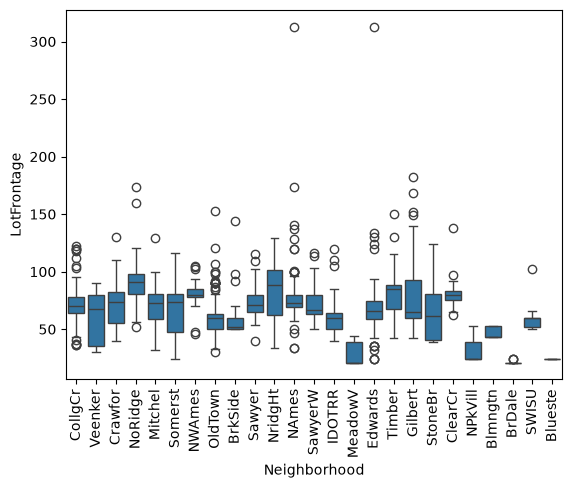

In [27]:
sns.boxplot(data =df, x = 'Neighborhood', y= 'LotFrontage')
plt.xticks(rotation = 90);

In [52]:
df['LotFrontage'] = df['LotFrontage'].fillna(
    df.groupby(['BldgType', 'Neighborhood'])['LotFrontage'].transform('mean')
)

df['LotFrontage'] = df['LotFrontage'].fillna(0)


In [29]:
null_df(df)

,Null Count,Null percent
GarageYrBlt,81,5.55
GarageFinish,81,5.55
GarageQual,81,5.55
GarageType,81,5.55
GarageCond,81,5.55
BsmtFinType2,38,2.60
BsmtExposure,38,2.60
BsmtQual,37,2.53
BsmtFinType1,37,2.53
BsmtCond,37,2.53


In [30]:
df[(df['GarageYrBlt'].isna()) | (df['GarageFinish'].isna()) | (df['GarageQual'].isna()) | (df['GarageType'].isna()) | (df['GarageCond'].isna())
    ]['GarageArea'].value_counts()

GarageArea
0    81
Name: count, dtype: int64

In [53]:
df[['GarageQual','GarageFinish','GarageType','GarageCond']] = df[['GarageQual','GarageFinish','GarageType','GarageCond']].fillna('NA')
df['GarageYrBlt'] = df['GarageYrBlt'].fillna(0)


In [32]:
null_df(df)

,Null Count,Null percent
BsmtExposure,38,2.60
BsmtFinType2,38,2.60
BsmtQual,37,2.53
BsmtFinType1,37,2.53
BsmtCond,37,2.53
MasVnrArea,8,0.55
Electrical,1,0.07


In [54]:
df[['BsmtExposure','BsmtFinType2','BsmtQual','BsmtFinType1','BsmtCond']] = df[['BsmtExposure','BsmtFinType2','BsmtQual','BsmtFinType1','BsmtCond']].fillna('NA')

In [35]:
null_df(df)

,Null Count,Null percent
MasVnrArea,8,0.55
Electrical,1,0.07


In [36]:
df[df['MasVnrArea'].isna()]['MasVnrType'].value_counts()

MasVnrType
NA    8
Name: count, dtype: int64

In [55]:
df['MasVnrArea'] = df['MasVnrArea'].fillna(0)

In [56]:
df = df.dropna(subset=['Electrical'], axis=0)

In [39]:
null_df(df)

,Null Count,Null percent


In [40]:
df.corr(numeric_only = True)['SalePrice'].sort_values()[:-1]

KitchenAbvGr    -0.135935
EnclosedPorch   -0.128627
MSSubClass      -0.084230
OverallCond     -0.077924
YrSold          -0.028907
LowQualFinSF    -0.025620
Id              -0.021756
MiscVal         -0.021200
BsmtHalfBath    -0.016873
BsmtFinSF2      -0.011412
3SsnPorch        0.044571
MoSold           0.046380
PoolArea         0.092397
ScreenPorch      0.111419
BedroomAbvGr     0.168235
BsmtUnfSF        0.214446
BsmtFullBath     0.227082
GarageYrBlt      0.261413
LotArea          0.263837
HalfBath         0.284400
OpenPorchSF      0.315831
2ndFlrSF         0.319464
WoodDeckSF       0.324422
LotFrontage      0.343656
BsmtFinSF1       0.386436
Fireplaces       0.466968
MasVnrArea       0.472606
YearRemodAdd     0.507430
YearBuilt        0.523273
TotRmsAbvGrd     0.533779
FullBath         0.560881
1stFlrSF         0.605968
TotalBsmtSF      0.613905
GarageArea       0.623423
GarageCars       0.640473
GrLivArea        0.708618
OverallQual      0.791069
Name: SalePrice, dtype: float64

## 4. Quick EDA: target, correlations, skew

A right-skewed target (a few very expensive houses) hurts models trained on squared error, which is why the target is log-transformed.

In [152]:
num_cols = df.select_dtypes(exclude='object').columns
skews = df[num_cols].apply(skew).sort_values(key=abs, ascending=False)
print(skews)

Has_PoolArea         14.332948
3SsnPorch             7.724247
Has_3SsnPorch         7.603183
LowQualFinSF          7.449961
Has_LowQualFinSF      7.289275
TotalBsmtSF          -5.151375
Has_MiscVal           5.009456
KitchenAbvGr          4.482026
MultiKitchen          4.338692
BsmtHalfBath          4.097541
Has_BsmtHalfBath      3.853859
ScreenPorch           3.145786
Has_ScreenPorch       3.108691
LotFrontage          -2.734717
BsmtFinSF2            2.519864
Has_BsmtFinSF2        2.421938
BsmtUnfSF            -2.183234
EnclosedPorch         2.108950
Has_EnclosedPorch     2.044674
AvgRoomSize           0.841240
Has_BsmtFinSF1       -0.774717
OverallCond           0.691340
HalfBath              0.677275
TotRmsAbvGrd          0.676068
Fireplaces            0.647913
BsmtFinSF1           -0.619803
GarageAge             0.608212
HouseAge              0.607686
BsmtFullBath          0.594354
TotRoomsInclBath      0.557506
MasVnrArea            0.501880
RemodAge              0.501023
Qualityx

In [ ]:
for c in num_cols:
    fig, ax = plt.subplots(1, 3, figsize=(14,3))
    sns.histplot(df[c], kde=True, ax=ax[0])          # shape
    sns.boxplot(x=df[c], ax=ax[1]);                   # outliers / tail

In [57]:
df["SalePrice"] = np.log1p(df["SalePrice"])

In [59]:
log_cols = ["LotArea","LotFrontage","GrLivArea","1stFlrSF","TotalBsmtSF","BsmtFinSF1",
            "BsmtUnfSF","2ndFlrSF","MasVnrArea","OpenPorchSF","WoodDeckSF",
            "BsmtFinSF2","ScreenPorch","EnclosedPorch","3SsnPorch","LowQualFinSF"]
df[log_cols] = np.log1p(df[log_cols])

## 5. Feature engineering

Everything is inside one function, so it can be re-run safely and re-used on new data. Steps, in order:

| # | Step | Why |
|---|---|---|
| 1 | `log1p` of the target | symmetric target; errors become relative (a $10k miss on a cheap house counts more) |
| 2 | `Has_*` flags for zero-inflated columns | "has a porch at all" is informative on its own, and the size column is mostly zeros |
| 3 | `log1p` of skewed area columns | pulls in long right tails |
| 4 | Ages instead of years | `HouseAge`, `RemodAge`, `GarageAge` are comparable across sale years |
| 5 | Totals and ratios | bathrooms, rooms, average room size |
| 6 | Interactions | quality x size, quality x condition (helps the linear models most) |

**Known issue (kept on purpose):** the original garage-age line keeps `GarageYrBlt` only when it is **at or after the sale year** and otherwise replaces it with `YearBuilt`. That is almost never true, so `GarageAge` ends up identical to `HouseAge`. `FIX_GARAGE_AGE = False` keeps this so the earlier results stay reproducible. Set it to `True` to test the corrected version (a garage year outside `[YearBuilt, YrSold]` or a missing garage falls back to `YearBuilt`).

In [58]:
flag_cols = ["MiscVal","PoolArea","3SsnPorch","LowQualFinSF","BsmtFinSF2",
             "ScreenPorch","EnclosedPorch","MasVnrArea","WoodDeckSF",
             "OpenPorchSF","2ndFlrSF","BsmtFinSF1","BsmtHalfBath"]
for c in flag_cols:
    df[f"Has_{c}"] = (df[c] > 0).astype(int)

df["MultiKitchen"] = (df["KitchenAbvGr"] > 1).astype(int)

In [60]:
df["GarageYrBlt"] = df["GarageYrBlt"].where((df["GarageYrBlt"] >= df["YrSold"]), df["YearBuilt"])
df["GarageAge"] = df["YrSold"] - df["GarageYrBlt"]

df["HouseAge"]  = df["YrSold"] - df["YearBuilt"]
df["RemodAge"]  = df["YrSold"] - df["YearRemodAdd"]

df["MSSubClass"] = df["MSSubClass"].astype(str)
df = df.drop(["GarageYrBlt", "PoolArea", "MiscVal", "Id", "YearBuilt", "YearRemodAdd"], axis = 1 )

In [61]:
# Lets add derived features such as total area,age, total no of rooms, total no of bedrooms, avg room size
df['RemodDone'] = np.where((df['RemodAge'] != df['HouseAge']),1,0)
df['TotalNumBathrooms'] = (
    df['FullBath'] + (0.5 * df['HalfBath']) +
    df['BsmtFullBath'] + (0.5 * df['BsmtHalfBath'])
)
df['TotRoomsInclBath'] = df['TotRmsAbvGrd'] + df['TotalNumBathrooms']
df['AvgRoomSize'] = df['GrLivArea'] / df['TotRoomsInclBath']


In [62]:
df['QualityxSize'] = df['GrLivArea'] * df['OverallQual']
df['QualityxCond'] = df['OverallCond'] * df['OverallQual']

In [ ]:
df.describe(percentiles=[.01, .05, .5, .95, .99]).T[["min","1%","50%","99%","max"]]

## 6. Train/test split

One-hot encoding turns text columns into 0/1 columns. `drop_first=True` removes one redundant column per category. No scaling is done here: the `StandardScaler` sits **inside each model's Pipeline**, so during cross-validation it is fitted on the training folds only (no leakage).

*Small limitation:* the encoding and the `LotFrontage` group means were computed on all rows before the split. The target is not involved, so the leakage risk is small, but a fully strict version would put these steps inside the pipeline (as the `.py` script does).

In [63]:
x = pd.get_dummies(df.drop('SalePrice', axis =1), drop_first = True)
y = df['SalePrice']

In [ ]:
x.isna().sum() > 0

In [64]:
X_train, X_test, y_train_log, y_test_log = train_test_split(x, y, test_size=0.2, random_state=42)

## 7. Models and search spaces

- **Small spaces use `GridSearchCV`** (every combination is tried): ElasticNet, Ridge, KNN, SVR, DT.
- **Large spaces use `RandomizedSearchCV`** (`N_ITER` random draws): RF, ADA, GB, XGB. `randint(a, b)` draws integers `a..b-1`; `uniform(start, width)` draws from `[start, start+width]`; `loguniform(a, b)` samples evenly on a log scale (right for learning rates and penalties).
- Every model is a `Pipeline([scaler, model])`. Scaling matters for ElasticNet, Ridge, KNN and SVR. It does nothing useful for the tree models but is harmless, so one structure is used throughout.

In [117]:
models = { 'ElasticNet':(Pipeline([('scaler',StandardScaler()), ('mod',ElasticNet(max_iter = 50000))]), {'mod__alpha':np.logspace(-4, 2, 30), 'mod__l1_ratio':[0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0]}),
           'KNN':(Pipeline([('scaler',StandardScaler()), ('mod',KNeighborsRegressor(n_jobs = -1))]), {'mod__n_neighbors':np.arange(1,11)}),
           'SVR':(Pipeline([('scaler',StandardScaler()), ('mod',SVR())]), {'mod__C':[0.01,0.1,1,10,100], 'mod__kernel':['rbf','poly'],'mod__gamma':['auto','scale'], 'mod__degree':[2,3,4], 'mod__epsilon':[0.01,0.1]}),
           'DT':(Pipeline([('scaler',StandardScaler()), ('mod', DecisionTreeRegressor())]), {'mod__max_depth':np.arange(2,5),'mod__min_samples_leaf':np.arange(1,20)}),                                                                
           'RF':(Pipeline([('scaler',StandardScaler()), ('mod', RandomForestRegressor())]), {'mod__n_estimators':randint(100,600), 'mod__max_features': uniform(0.1, 0.4),'mod__min_samples_leaf':np.arange(2,20),'mod__max_depth':np.arange(2,20)}),                                                              
           'ADA':(Pipeline([('scaler',StandardScaler()), ('mod', AdaBoostRegressor(estimator = DecisionTreeRegressor()))]), {'mod__n_estimators':randint(300,1000),'mod__learning_rate':loguniform(0.02, 0.4), 'mod__estimator__min_samples_leaf':np.arange(2,30),'mod__estimator__max_depth':np.arange(2,8)}),                                                              
           'GB':(Pipeline([('scaler',StandardScaler()), ('mod', GradientBoostingRegressor())]), {'mod__n_estimators':randint(300,1500),'mod__learning_rate':loguniform(0.02, 0.4), 'mod__min_samples_leaf':np.arange(2,30,),'mod__max_depth':np.arange(2,15)}) ,                                                           
           'XGB':(Pipeline([('scaler',StandardScaler()), ('mod', XGBRegressor(tree_method='hist', random_state=101, n_jobs=1))]), {'mod__n_estimators':     randint(300, 1500),
                   'mod__learning_rate':    loguniform(0.01, 0.1),
                   'mod__max_depth':        randint(2, 6),
                   'mod__min_child_weight': randint(1, 11),
                   'mod__subsample':        uniform(0.6, 0.4),
                   'mod__colsample_bytree': uniform(0.3, 0.7),
                   'mod__reg_lambda':       loguniform(0.5, 20),
                   'mod__reg_alpha':        loguniform(1e-3, 1)})

}

In [119]:
best_params = {}
rmse ={}
r2 ={}
mae ={}
features_imp ={}
large = {'RF','ADA','GB','XGB'}

for name,(pipe,grid) in models.items():
    if name in large:
         gs = RandomizedSearchCV(pipe, grid, n_iter=60,verbose =2,
                                scoring="neg_root_mean_squared_error", n_jobs=-1)
    else:
        gs = GridSearchCV(pipe,grid,scoring="neg_root_mean_squared_error", n_jobs=-1,verbose =2)
    
    gs.fit(X_train,y_train_log)
    y_pred_log = gs.predict(X_test)
    y_pred = np.expm1(y_pred_log)
    y_test = np.expm1(y_test_log)

    best_params[name] = gs.best_params_

    rmse[name] = np.sqrt(mean_squared_error(y_test, y_pred))
    mae[name]  = mean_absolute_error(y_test, y_pred)
    r2[name]   = r2_score(y_test, y_pred)

    model = gs.best_estimator_.named_steps["mod"]      # the model inside the pipeline
    if hasattr(model, "coef_"):
        features_imp[name] = pd.Series(np.ravel(model.coef_), index=X_train.columns)
    elif hasattr(model, "feature_importances_"):
        features_imp[name] = pd.Series(model.feature_importances_, index=X_train.columns)
    else:
        features_imp[name] = None  
    print(f'{name} completed')     

Fitting 5 folds for each of 300 candidates, totalling 1500 fits
ElasticNet completed
Fitting 5 folds for each of 10 candidates, totalling 50 fits
KNN completed
Fitting 5 folds for each of 120 candidates, totalling 600 fits
SVR completed
Fitting 5 folds for each of 57 candidates, totalling 285 fits
DT completed
Fitting 5 folds for each of 60 candidates, totalling 300 fits
RF completed
Fitting 5 folds for each of 60 candidates, totalling 300 fits
ADA completed
Fitting 5 folds for each of 60 candidates, totalling 300 fits
GB completed
Fitting 5 folds for each of 60 candidates, totalling 300 fits
XGB completed


In [120]:
best_params

{'ElasticNet': {'mod__alpha': np.float64(0.07880462815669913),
  'mod__l1_ratio': 0.1},
 'KNN': {'mod__n_neighbors': np.int64(9)},
 'SVR': {'mod__C': 10,
  'mod__degree': 3,
  'mod__epsilon': 0.01,
  'mod__gamma': 'auto',
  'mod__kernel': 'poly'},
 'DT': {'mod__max_depth': np.int64(4), 'mod__min_samples_leaf': np.int64(12)},
 'RF': {'mod__max_depth': np.int64(11),
  'mod__max_features': np.float64(0.23919458682139516),
  'mod__min_samples_leaf': np.int64(2),
  'mod__n_estimators': 315},
 'ADA': {'mod__estimator__max_depth': np.int64(7),
  'mod__estimator__min_samples_leaf': np.int64(4),
  'mod__learning_rate': np.float64(0.1112542732836378),
  'mod__n_estimators': 465},
 'GB': {'mod__learning_rate': np.float64(0.025995072770998176),
  'mod__max_depth': np.int64(2),
  'mod__min_samples_leaf': np.int64(25),
  'mod__n_estimators': 1486},
 'XGB': {'mod__colsample_bytree': np.float64(0.5724906851700184),
  'mod__learning_rate': np.float64(0.024153860874989524),
  'mod__max_depth': 3,
  'mod

## 8. Compare models

Models are ranked by **CV RMSLE**. `cv_std` is how much that score moves between folds. If two models differ by less than `cv_std` they cannot be separated, so the notebook reports a *group* of top models, not a single winner.

In [123]:
rmse

{'ElasticNet': np.float64(20312.632908190713),
 'KNN': np.float64(34084.55235619528),
 'SVR': np.float64(25454.130068979714),
 'DT': np.float64(37081.38427793173),
 'RF': np.float64(23384.3983546298),
 'ADA': np.float64(25025.765522878693),
 'GB': np.float64(20861.38169890763),
 'XGB': np.float64(20709.590500572118)}

In [124]:
mae

{'ElasticNet': 14606.96649986487,
 'KNN': 24443.72727076045,
 'SVR': 17118.941472930783,
 'DT': 27466.51092392713,
 'RF': 16162.469861477193,
 'ADA': 18034.437583301573,
 'GB': 14967.936620942935,
 'XGB': 14934.701359160956}

## ElasticNet, XGB and Gradient Boosted Decision Trees performed best.

In [168]:
fe = features_imp['ElasticNet'].sort_values()
fe_imp = pd.concat([fe[fe!=0].head(10), fe[fe!=0].tail(10)], axis = 0 )
fe_imp

HouseAge               -0.024925
RemodAge               -0.020289
PoolQC_Gd              -0.014317
Condition2_PosN        -0.013510
GarageAge              -0.012875
MultiKitchen           -0.012071
MSZoning_RM            -0.010213
ExterQual_TA           -0.009322
Exterior1st_BrkComm    -0.007710
Neighborhood_Edwards   -0.006782
Neighborhood_NridgHt    0.019534
TotRoomsInclBath        0.020967
OverallQual             0.021794
TotalNumBathrooms       0.024493
GarageCars              0.027687
LotArea                 0.032760
1stFlrSF                0.035802
QualityxSize            0.040692
QualityxCond            0.046920
GrLivArea               0.069730
dtype: float64

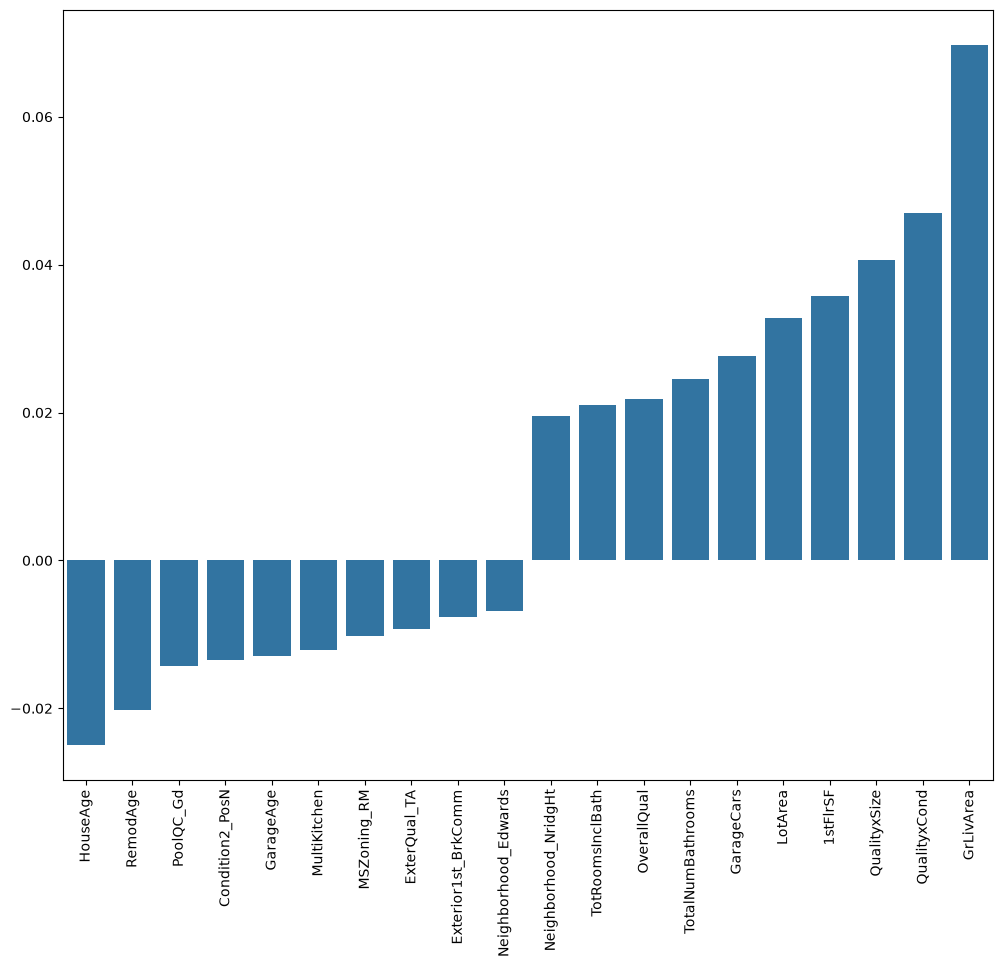

In [172]:
plt.figure(figsize = (12,10))
sns.barplot(fe_imp)
plt.xticks(rotation = 90);

## 10. Conclusion and Limitations

**What this shows**

- **A top group of three:** ElasticNet, XGBoost and Gradient Boosting reached an RMSE of about $20.3k-$20.9k (11-11.5% of the mean price), within about 3% of each other. On one 292-house test split that gap is noise, so no ranking among them is claimed. Use the CV table in section 9 for that.
- **Mid group:** Random Forest, AdaBoost and SVR followed at $23k-$25k.
- **Clearly worse:** KNN and a single decision tree ($34k-$37k).
- **The signal is mostly additive.** A regularised linear model matched boosted trees, and the best trees were shallow (GB depth 2, XGB depth 3, DT depth 4). Gains came from regularisation and feature engineering, not from model complexity.
- Fill in after the rerun: tied group (section 9), stacking gain vs `cv_std` (section 13), main drivers (section 11).

**Limitations**

- **Garage age:** `GarageAge` equals `HouseAge` unless `FIX_GARAGE_AGE = True`.
- **Leakage (minor):** one-hot encoding and the `LotFrontage` group means were computed before the split.
- **Small test set:** about 292 houses, so differences under a few percent are not reliable.
- **Tail errors:** expensive or unusual houses drive the RMSE (section 12).
- **No outlier removal** beyond the log transforms.

## "This was a learning exercise so we did do mulitple hyper parameter tuning rounds and did not stack the models."